In [25]:

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Xác định thư mục gốc của project
PROJECT_DIR = Path.cwd().parent

# Thêm project vào đường dẫn Python
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from ml.data import load_all

# Đọc dữ liệu từ data/raw
data = load_all(PROJECT_DIR / "data" / "raw")

# Gộp train, valid, test để khám phá dữ liệu
df = pd.concat(
    [frame.assign(split=name) for name, frame in data.items()],
    ignore_index=True
)

print("Thư mục project:", PROJECT_DIR)
print("Kích thước dữ liệu:", df.shape)
display(df.head())


[WARNING] d:\apk\filecode\student-feedback-ai\data\raw\UIT-VSFC_valid.csv: 1 dòng text rỗng; 1 dòng label rỗng.
Thư mục project: d:\apk\filecode\student-feedback-ai
Kích thước dữ liệu: (16175, 3)


,text,label,split
0,slide giáo trình đầy đủ .,positive,train
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",positive,train
2,đi học đầy đủ full điểm chuyên cần .,negative,train
3,chưa áp dụng công nghệ thông tin và các thiết ...,negative,train
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",positive,train


In [26]:
print("Tổng số dòng:", len(df))
print("\nSố dòng theo split:")
print(df.groupby("split").size())

print("\nSố dòng theo nhãn:")
print(df["label"].value_counts())

print("\nSố dòng theo nhãn và split:")
print(pd.crosstab(df["split"], df["label"]))
for split, frame in data.items():
    print(f"\nPhân bố nhãn - {split}")

    counts = frame["label"].value_counts()
    percentages = frame["label"].value_counts(normalize=True) * 100

    result = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": percentages.round(2)
    })

    print(result)

Tổng số dòng: 16175

Số dòng theo split:
split
test      3166
train    11426
valid     1583
dtype: int64

Số dòng theo nhãn:
label
positive    8038
negative    7439
neutral      698
Name: count, dtype: int64

Số dòng theo nhãn và split:
label  negative  neutral  positive
split                             
test       1409      167      1590
train      5325      458      5643
valid       705       73       805

Phân bố nhãn - train
          Số lượng  Tỷ lệ (%)
label                        
positive      5643      49.39
negative      5325      46.60
neutral        458       4.01

Phân bố nhãn - valid
          Số lượng  Tỷ lệ (%)
label                        
positive       805      50.85
negative       705      44.54
neutral         73       4.61

Phân bố nhãn - test
          Số lượng  Tỷ lệ (%)
label                        
positive      1590      50.22
negative      1409      44.50
neutral        167       5.27


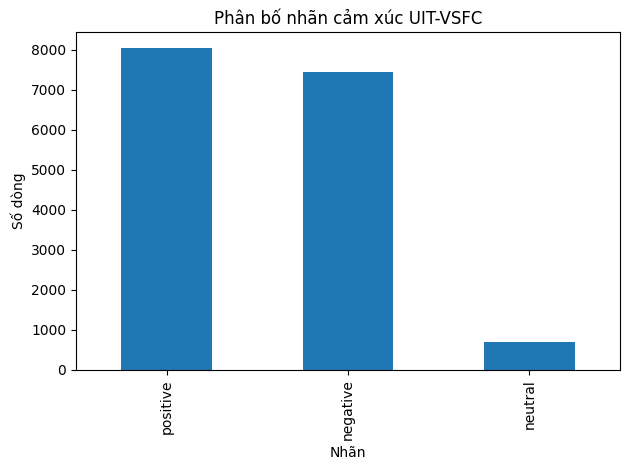

In [27]:
label_counts = df["label"].value_counts()

ax = label_counts.plot(kind="bar")
ax.set_title("Phân bố nhãn cảm xúc UIT-VSFC")
ax.set_xlabel("Nhãn")
ax.set_ylabel("Số dòng")
plt.tight_layout()
plt.show()

       text_length_chars  text_length_words
count       16175.000000       16175.000000
mean           58.769212          14.229119
std            43.264570          10.103731
min             4.000000           2.000000
25%            31.000000           8.000000
50%            46.000000          11.000000
75%            73.000000          17.000000
max           718.000000         161.000000


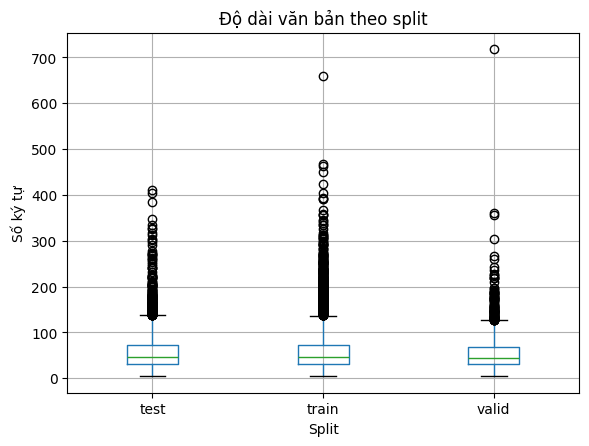

In [28]:
df["text_length_chars"] = df["text"].str.len()
df["text_length_words"] = df["text"].str.split().str.len()

print(df[["text_length_chars", "text_length_words"]].describe())

df.boxplot(column="text_length_chars", by="split")
plt.title("Độ dài văn bản theo split")
plt.suptitle("")
plt.xlabel("Split")
plt.ylabel("Số ký tự")
plt.show()

In [29]:
for split, part in df.groupby("split"):
    print(
        split,
        "số dòng =", len(part),
        "| số văn bản duy nhất =", part["text"].nunique(),
        "| số dòng thuộc nhóm trùng =",
        part["text"].duplicated(keep=False).sum(),
    )

for left in ("train", "valid", "test"):
    for right in ("train", "valid", "test"):
        if left >= right:
            continue

        a = set(df.loc[df["split"] == left, "text"])
        b = set(df.loc[df["split"] == right, "text"])
        print(f"{left} ↔ {right}: {len(a & b)} văn bản trùng")

test số dòng = 3166 | số văn bản duy nhất = 3166 | số dòng thuộc nhóm trùng = 0
train số dòng = 11426 | số văn bản duy nhất = 11425 | số dòng thuộc nhóm trùng = 2
valid số dòng = 1583 | số văn bản duy nhất = 1583 | số dòng thuộc nhóm trùng = 0
train ↔ valid: 0 văn bản trùng
test ↔ train: 0 văn bản trùng
test ↔ valid: 0 văn bản trùng
